# 🚄 Régularité des TGV : exploration des données

**Projet IADATA 700 · données SNCF Open Data**

Ce notebook explore la régularité mensuelle des TGV par liaison, puis prépare le croisement avec les données sur les gares et les lignes à grande vitesse.

### Jeux de données utilisés

| Jeu de données | Contenu | Identifiant |
|---|---|---|
| Régularité mensuelle TGV par liaisons (AQST) | Retards, annulations et causes de retard, par mois et par liaison | `regularite-mensuelle-tgv-aqst` |
| Liste des gares | Gares du réseau, avec leur ligne et leurs coordonnées | `liste-des-gares` |
| Lignes LGV et par écartement | Lignes ferroviaires et leur catégorie (`catlig`) | `lignes-lgv-et-par-ecartement` |

> **Définition SNCF d'un train à l'heure** : retard au terminus inférieur à 5 min pour un parcours de moins de 1h30, 10 min entre 1h30 et 3h, 15 min au-delà de 3h.
> Les chiffres par liaison ne doivent pas être additionnés pour retrouver une régularité globale : un même TGV peut compter dans plusieurs liaisons.

### Plan

1. Imports et chargement
2. Qualité des données
3. Distribution des retards
4. Causes des retards
5. Liaisons et gares
6. Gares et lignes à grande vitesse
7. Nettoyage des noms de gares
8. Vérification : toutes les gares sont-elles dans la liste des gares ?
9. Synthèse et prochaines étapes

## 1. Imports et chargement

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import squarify

In [2]:
sns.set_theme(style="whitegrid", palette="Set2")

Chargement du jeu de données de régularité.

In [3]:
dataset_path = "../data/raw/regularite-mensuelle-tgv-aqst.csv"

df_raw = pd.read_csv(dataset_path)
print(df_raw.shape)
print(df_raw.head().to_markdown())

(12907, 26)
|    | date    | service   | gare_depart        | gare_arrivee       |   duree_moyenne |   nb_train_prevu |   nb_annulation |   commentaire_annulation |   nb_train_depart_retard |   retard_moyen_depart |   retard_moyen_tous_trains_depart |   commentaire_retards_depart |   nb_train_retard_arrivee |   retard_moyen_arrivee |   retard_moyen_tous_trains_arrivee | commentaires_retard_arrivee                                                      |   nb_train_retard_sup_15 |   retard_moyen_trains_retard_sup15 |   nb_train_retard_sup_30 |   nb_train_retard_sup_60 |   prct_cause_externe |   prct_cause_infra |   prct_cause_gestion_trafic |   prct_cause_materiel_roulant |   prct_cause_gestion_gare |   prct_cause_prise_en_charge_voyageurs |
|---:|:--------|:----------|:-------------------|:-------------------|----------------:|-----------------:|----------------:|-------------------------:|-------------------------:|----------------------:|----------------------------------:|------------

## 2. Qualité des données

Types, valeurs distinctes et valeurs manquantes pour chaque colonne.

In [4]:
df_infos = pd.DataFrame(
    {
        "type": df_raw.dtypes.astype(str),
        "valeurs_distinctes": df_raw.nunique(),
        "valeurs_nulles": df_raw.isnull().sum(),
        "pourcentage_manquant": (df_raw.isnull().mean() * 100).round(2),
    }
)

print(df_infos.to_markdown())


|                                      | type    |   valeurs_distinctes |   valeurs_nulles |   pourcentage_manquant |
|:-------------------------------------|:--------|---------------------:|-----------------:|-----------------------:|
| date                                 | str     |                  105 |                0 |                   0    |
| service                              | str     |                    2 |                0 |                   0    |
| gare_depart                          | str     |                   59 |                0 |                   0    |
| gare_arrivee                         | str     |                   59 |                0 |                   0    |
| duree_moyenne                        | int64   |                  411 |                0 |                   0    |
| nb_train_prevu                       | int64   |                  908 |                0 |                   0    |
| nb_annulation                        | int64   |      

**Constats**

- `commentaire_annulation` et `commentaire_retards_depart` sont **vides à 100 %** : colonnes à supprimer au nettoyage.
- `commentaires_retard_arrivee` est manquante à **94,6 %** : très peu exploitable.
- Aucune autre colonne n'a de valeur manquante.
- Le jeu compte 105 mois distincts, 2 types de service, et 59 gares de départ comme d'arrivée.

## 3. Distribution des retards

Retards moyens au départ et à l'arrivée, pour les trains en retard et pour l'ensemble des trains.

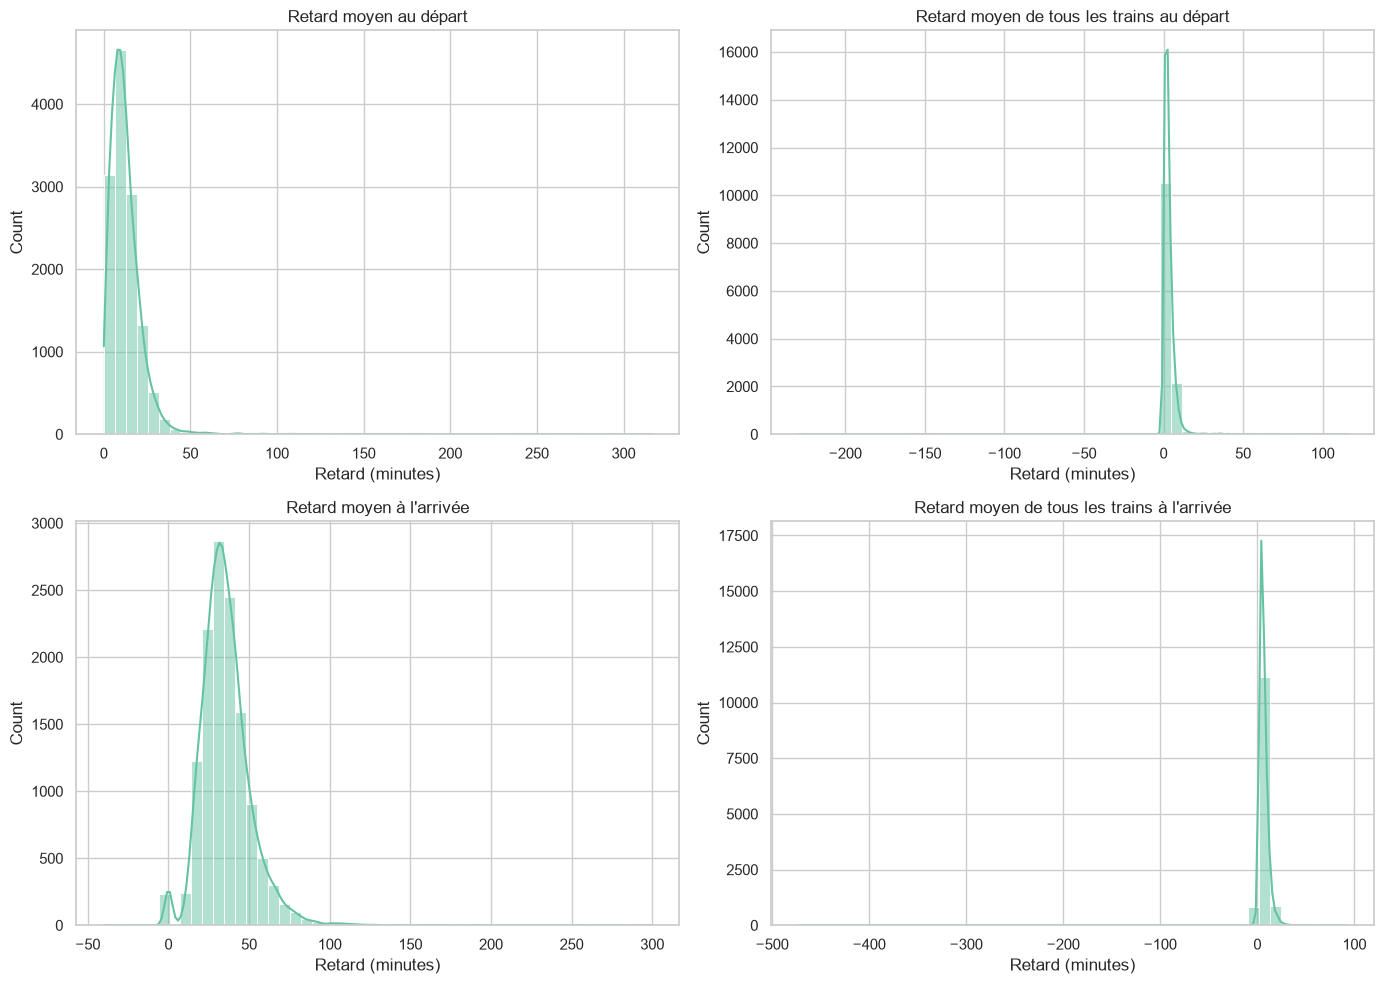

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- DÉPART ---

sns.histplot(data=df_raw, x="retard_moyen_depart", bins=50, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Retard moyen au départ")
axes[0, 0].set_xlabel("Retard (minutes)")

sns.histplot(
    data=df_raw, x="retard_moyen_tous_trains_depart", bins=50, kde=True, ax=axes[0, 1]
)
axes[0, 1].set_title("Retard moyen de tous les trains au départ")
axes[0, 1].set_xlabel("Retard (minutes)")


# --- ARRIVÉE ---

sns.histplot(data=df_raw, x="retard_moyen_arrivee", bins=50, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Retard moyen à l'arrivée")
axes[1, 0].set_xlabel("Retard (minutes)")

sns.histplot(
    data=df_raw, x="retard_moyen_tous_trains_arrivee", bins=50, kde=True, ax=axes[1, 1]
)
axes[1, 1].set_title("Retard moyen de tous les trains à l'arrivée")
axes[1, 1].set_xlabel("Retard (minutes)")


plt.tight_layout()
plt.show()

Valeur minimale du retard moyen à l'arrivée (tous trains) :

In [6]:
print(min(df_raw["retard_moyen_tous_trains_arrivee"]))

-472.6388889


> ⚠️ **Anomalie** : le minimum est très négatif (environ −472 min, soit près de 8 h d'avance). Un retard moyen ne peut pas atteindre une telle valeur : la SNCF n'est jamais en avance de cette ampleur. Ces valeurs aberrantes sont à traiter au nettoyage.

## 4. Causes des retards

Part moyenne de chaque cause sur l'ensemble du jeu de données. C'est une moyenne simple : elle n'est pas pondérée par le nombre de trains de chaque liaison.

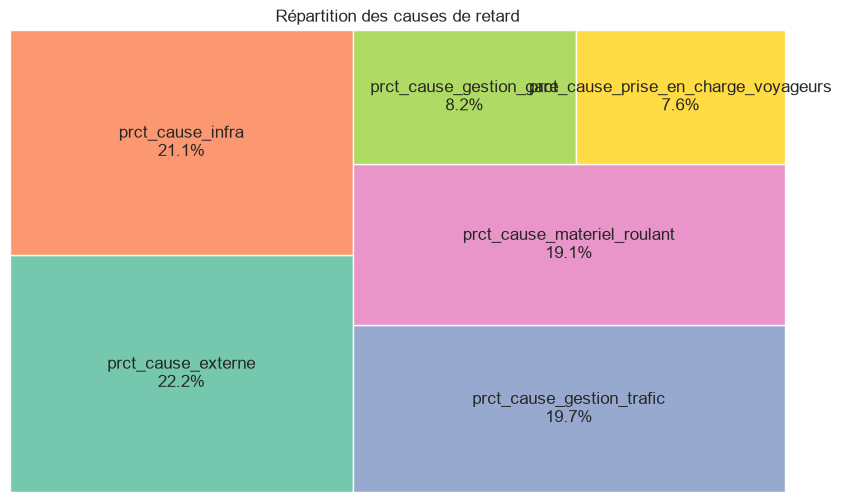

In [7]:
cols = [
    "prct_cause_externe",
    "prct_cause_infra",
    "prct_cause_gestion_trafic",
    "prct_cause_materiel_roulant",
    "prct_cause_gestion_gare",
    "prct_cause_prise_en_charge_voyageurs",
]

values = df_raw[cols].mean()

plt.figure(figsize=(10, 6))

squarify.plot(
    sizes=values,
    label=[f"{x}\n{y:.1f}%" for x, y in zip(cols, values)],
    color=sns.color_palette("Set2", 6),
    alpha=0.9,
)

plt.axis("off")
plt.title("Répartition des causes de retard")
plt.show()

## 5. Liaisons et gares

Couples distincts gare de départ / gare d'arrivée présents dans le jeu de données.

In [8]:
couples_gares = df_raw[['gare_depart', 'gare_arrivee']].drop_duplicates()
print(couples_gares.to_markdown())


|     | gare_depart                    | gare_arrivee                   |
|----:|:-------------------------------|:-------------------------------|
|   0 | BORDEAUX ST JEAN               | PARIS MONTPARNASSE             |
|   1 | LE MANS                        | PARIS MONTPARNASSE             |
|   2 | PARIS MONTPARNASSE             | LA ROCHELLE VILLE              |
|   3 | PARIS MONTPARNASSE             | NANTES                         |
|   4 | POITIERS                       | PARIS MONTPARNASSE             |
|   5 | ST MALO                        | PARIS MONTPARNASSE             |
|   6 | TOULOUSE MATABIAU              | PARIS MONTPARNASSE             |
|   7 | VANNES                         | PARIS MONTPARNASSE             |
|   8 | REIMS                          | PARIS EST                      |
|   9 | DOUAI                          | PARIS NORD                     |
|  10 | LILLE                          | PARIS NORD                     |
|  11 | LILLE                         

## 6. Gares et lignes à grande vitesse

**Question :** les liaisons circulent-elles sur les mêmes rails ? La réponse conditionne le nettoyage des données.

### Chargement des jeux de données sur les gares et les lignes

In [9]:
dataset_gares_path = "../data/raw/liste-des-gares.csv"
dataset_lines_path = "../data/raw/lignes-lgv-et-par-ecartement.csv"

df_gares_raw = pd.read_csv(dataset_gares_path)
print(df_gares_raw.shape)
print(df_gares_raw.head().to_markdown())

df_lines_raw = pd.read_csv(dataset_lines_path)
print(df_lines_raw.shape)
print(df_lines_raw.head().to_markdown())

(6469, 18)
|    |   code_uic | libelle        | fret   | voyageurs   |   code_ligne |   rg_troncon | pk      | commune        | departemen          |   idreseau | idgaia                               |   x_l93 |       y_l93 |   x_wgs84 |   y_wgs84 | c_geo                                   | geo_point_2d                            | geo_shape                                                                  |
|---:|-----------:|:---------------|:-------|:------------|-------------:|-------------:|:--------|:---------------|:--------------------|-----------:|:-------------------------------------|--------:|------------:|----------:|----------:|:----------------------------------------|:----------------------------------------|:---------------------------------------------------------------------------|
|  0 |   87731448 | Porte Maillot  | N      | O           |       979000 |            1 | 005+500 | PARIS          | PARIS               |     109993 | 3964dfe0-0a8a-11ec-b1ff-01bcb2273146 

### Filtre sur les lignes à grande vitesse

On garde les lignes de catégorie « Ligne à grande vitesse », puis les gares situées sur ces lignes.

In [18]:
df_gares_raw[df_gares_raw["libelle"] == "Bordeaux-St-Jean"]

,code_uic,libelle,fret,voyageurs,code_ligne,rg_troncon,pk,commune,departemen,idreseau,idgaia,x_l93,y_l93,x_wgs84,y_wgs84,c_geo,geo_point_2d,geo_shape
1761,87581009,Bordeaux-St-Jean,O,O,655000,1,000+000,BORDEAUX,GIRONDE,113151,e001860e-19bf-11e5-82ff-01fc64e0362d,419015.4944,6.420413e+06,-0.555978,44.825923,"44.82592310199666, -0.5559775161877916","44.825923101976585, -0.5559775161877943","{""coordinates"": [-0.555977516187794, 44.825923..."
1833,87581009,Bordeaux-St-Jean,O,O,570000,3,583+844,BORDEAUX,GIRONDE,113551,e001860e-19bf-11e5-82ff-01fc64e0362d,419019.7653,6.420426e+06,-0.555931,44.826041,"44.82604094019732, -0.5559308913518892","44.82604094017726, -0.5559308913518917","{""coordinates"": [-0.555930891351892, 44.826040..."
5923,87581009,Bordeaux-St-Jean,O,O,640000,1,000+000,BORDEAUX,GIRONDE,114494,e001860e-19bf-11e5-82ff-01fc64e0362d,419015.4944,6.420413e+06,-0.555978,44.825923,"44.82592310199666, -0.5559775161877916","44.825923101976585, -0.5559775161877943","{""coordinates"": [-0.555977516187794, 44.825923..."


In [23]:
df_lines_raw[df_lines_raw["code_ligne"] == 655000]

,code_ligne,lib_ligne,catlig,rg_troncon,pkd,pkf,idgaia,x_d_l93,y_d_l93,x_f_l93,y_f_l93,x_d_wgs84,y_d_wgs84,x_f_wgs84,y_f_wgs84,c_geo_d,c_geo_f,geo_point_2d,geo_shape
39,655000,655000,Ligne du réseau conventionnel à écartement normal,1,000+000,235+063,777b3842-e28c-11e8-92ff-01b064e0362d,419015.4944,6.420413e+06,310545.8681,6.260623e+06,-0.555978,44.825923,-1.802873,43.33812,"44.82592310199666, -0.5559775161877916","43.33811986489555, -1.802873494508197","44.02377137626735, -1.1103676334588324","{""coordinates"": [[-0.555977516187794, 44.82592..."
1550,655000,655000,Ligne du réseau conventionnel à écartement normal,1,NaN,NaN,NaN,419015.4944,6.420413e+06,310545.8681,6.260623e+06,-0.555978,44.825923,-1.802873,43.33812,"44.82592310199666, -0.5559775161877916","43.33811986489555, -1.802873494508197","44.02377137626735, -1.1103676334588324","{""coordinates"": [[-0.555977516187794, 44.82592..."


In [ ]:
df_lgv = df_lines_raw[df_lines_raw["catlig"] == "Ligne à grande vitesse"]
numeros_lgv = df_lgv["code_ligne"].unique()
df_gares_lgv_raw = df_gares_raw[df_gares_raw["code_ligne"].isin(numeros_lgv)]

print(df_gares_lgv_raw.to_markdown())
df_gares_lgv_raw.shape

|      |   code_uic | libelle                        | fret   | voyageurs   |   code_ligne |   rg_troncon | pk      | commune            | departemen            |   idreseau | idgaia                               |   x_l93 |       y_l93 |   x_wgs84 |   y_wgs84 | c_geo                                  | geo_point_2d                           | geo_shape                                                                 |
|-----:|-----------:|:-------------------------------|:-------|:------------|-------------:|-------------:|:--------|:-------------------|:----------------------|-----------:|:-------------------------------------|--------:|------------:|----------:|----------:|:---------------------------------------|:---------------------------------------|:--------------------------------------------------------------------------|
|  352 |   87171926 | Champagne-Ardenne-TGV          | N      | O           |         5000 |            1 | 113+767 | BEZANNES           | MARNE              

(31, 18)

## 7. Nettoyage des noms de gares

Les noms de gares ne s'écrivent pas de la même façon dans les deux sources (par exemple `Lyon-St-Exupéry-TGV` dans la liste des gares). Pour pouvoir les comparer, on applique la même normalisation aux deux :

- tout en **majuscules** ;
- **accents supprimés** (`É` devient `E`) ;
- **tirets remplacés par des espaces** ;
- espaces multiples et espaces en début ou fin de nom supprimés.

Les jeux bruts (`df_raw`, `df_gares_raw`) ne sont pas modifiés : on travaille sur des copies.

In [11]:
def normaliser_noms(s: pd.Series) -> pd.Series:
    """Majuscules, sans accents, tirets remplacés par des espaces."""
    return (
        s.str.upper()
        .str.normalize("NFKD")  # sépare la lettre de son accent : É -> E + ´
        .str.encode("ascii", errors="ignore")  # supprime les accents
        .str.decode("ascii")
        .str.replace("-", " ", regex=False)
        .str.replace(r"\s+", " ", regex=True)  # espaces multiples -> un seul
        .str.strip()
    )

In [12]:
df_regularite = df_raw.copy()
for col in ["gare_depart", "gare_arrivee"]:
    df_regularite[col] = normaliser_noms(df_regularite[col])

df_gares_lgv_cleaned = df_gares_lgv_raw.copy()
df_gares_lgv_cleaned["gare"] = normaliser_noms(df_gares_lgv_cleaned["libelle"])

Vérification visuelle : quelques noms avant et après normalisation.

In [13]:
df_gares_lgv_cleaned[["libelle", "gare"]].drop_duplicates()

,libelle,gare
352,Champagne-Ardenne-TGV,CHAMPAGNE ARDENNE TGV
424,Valence-TGV,VALENCE TGV
563,Besançon-Franche-Comté-TGV,BESANCON FRANCHE COMTE TGV
775,Lyon-St-Exupéry-TGV,LYON ST EXUPERY TGV
788,Vendôme-Villiers-sur-Loir,VENDOME VILLIERS SUR LOIR
822,Lyon-St-Clair,LYON ST CLAIR
1247,Allan,ALLAN
1547,Pasilly,PASILLY
1846,Senas-TGV,SENAS TGV
1876,Avignon-TGV,AVIGNON TGV


## 8. Vérification : toutes les gares sont-elles dans la liste des gares ?

1. On regroupe les gares de départ et d'arrivée dans une seule colonne.
2. On garde les valeurs distinctes.
3. On fusionne (`merge`) avec la liste des gares : l'option `indicator=True` ajoute une colonne `_merge` qui indique si la gare a été trouvée (`both`) ou non (`left_only`).

In [14]:
gares_regularite = (
    pd.concat([df_regularite["gare_depart"], df_regularite["gare_arrivee"]])
    .dropna()
    .drop_duplicates()
    .sort_values()
    .to_frame(name="gare")
    .reset_index(drop=True)
)
print(f"{len(gares_regularite)} gares distinctes dans le jeu de régularité")

59 gares distinctes dans le jeu de régularité


In [15]:
verif = gares_regularite.merge(
    df_gares_lgv_cleaned[["gare"]].drop_duplicates(),
    on="gare",
    how="left",
    indicator=True,
)

manquantes = verif.loc[verif["_merge"] == "left_only", ["gare"]].reset_index(drop=True)

print(f"Trouvées : {(verif['_merge'] == 'both').sum()} / {len(verif)}")
print(f"Absentes de la liste des gares : {len(manquantes)}")
manquantes

Trouvées : 4 / 59
Absentes de la liste des gares : 55


,gare
0,ANGERS SAINT LAUD
1,ANGOULEME
2,ANNECY
3,ARRAS
4,BARCELONA
5,BELLEGARDE (AIN)
6,BORDEAUX ST JEAN
7,BREST
8,CHAMBERY CHALLES LES EAUX
9,DIJON VILLE


Une gare absente n'est pas forcément une erreur. Deux explications sont probables, à confirmer avec la liste ci-dessus :

- **Gares étrangères** : `BARCELONA`, `MADRID`, `FRANCFORT`, `ZURICH`, `GENEVE`... figurent dans les liaisons mais ne sont sans doute pas dans une liste de gares françaises.
- **Noms différents d'une source à l'autre** : par exemple `PARIS LYON` côté régularité, probablement un autre libellé côté liste des gares. Ces cas se règlent avec un dictionnaire de correspondance, à construire à partir de la liste des gares absentes.

## 9. Synthèse et prochaines étapes

- [ ] Supprimer les colonnes vides (`commentaire_annulation`, `commentaire_retards_depart`).
- [ ] Traiter les retards moyens négatifs aberrants.
- [ ] Construire un dictionnaire de correspondance pour les gares absentes de la liste des gares.
- [ ] Décider du traitement des gares étrangères.
- [ ] Déplacer `normaliser_noms` dans `src/` pour la réutiliser dans les autres notebooks.